# Example

This notebook show an example how to extract a MODIS NIR mean time series inside a glaicier outline and Sentinel-1 and Sentinel-2 glacier snow cover fractions. Run the cells in order after installing the dependencies in `README.md`. Google Earth Engine access is required.

In [1]:
import ee
import geemap
from datetime import date, timedelta

import matplotlib.pyplot as plt

# Authenticate once on this machine if needed:
# ee.Authenticate()
ee.Initialize(project="YOUR_EARTH_ENGINE_PROJECT")


from glacier_scaf import MODIS_meanNIR, SCAF_S1, SCAF_S2

## Glacier and period selection

In this example Zulmat glacier (RGI id: RGI60-13.14451) is used. Change the ID or supply another EE geometry for a different glacier.

In [2]:
start_date = "2018-06-01"
end_date = "2018-09-30"
glacier = ee.FeatureCollection("users/josiaszeller/RGVI_v6").filter(ee.Filter.eq('RGIId', 'RGI60-13.14451')).first() \
    .set('Name', 'Zulmart')
glacier_outline = glacier.geometry()

Map = geemap.Map()
Map.centerObject(glacier_outline, 12)
Map.addLayer(glacier_outline, {'color': 'red'}, 'glacier outline', True, 0.6);
Map

Map(center=[38.8631658918276, 72.99896883020456], controls=(WidgetControl(options=['position', 'transparent_bg…

## MODIS mean NIR time series

In [3]:
modis_nir = MODIS_meanNIR(glacier_outline, start_date, end_date)

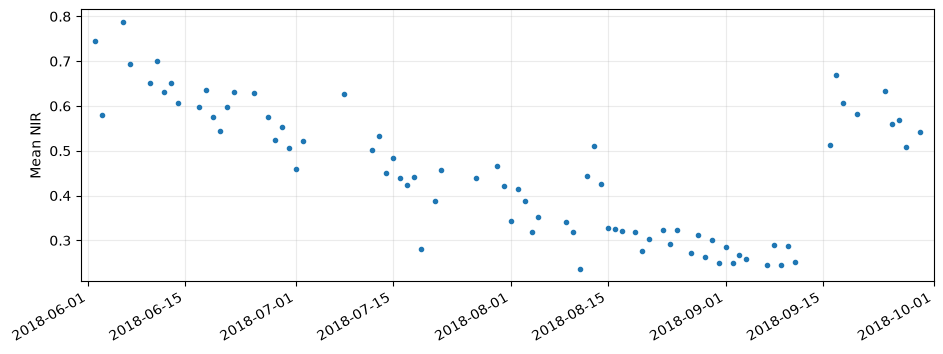

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(modis_nir.index, modis_nir.values, marker=".", linestyle="")
ax.set(ylabel="Mean NIR")
ax.grid(alpha=0.25)
ax.set_xlim(
    date.fromisoformat(start_date) - timedelta(days=1),
    date.fromisoformat(end_date) + timedelta(days=1),
)
fig.autofmt_xdate()
plt.show()

## Sentinel-1 and Sentinel-2 snow cover fraction time series

In [5]:
s1_scaf = SCAF_S1(start_date, end_date, glacier_outline, 'ASCENDING')

In [6]:
s2_scaf = SCAF_S2(start_date, end_date, glacier_outline, th_min=4000, th_max=5500, th_fixed=4500, tile='43SCD')

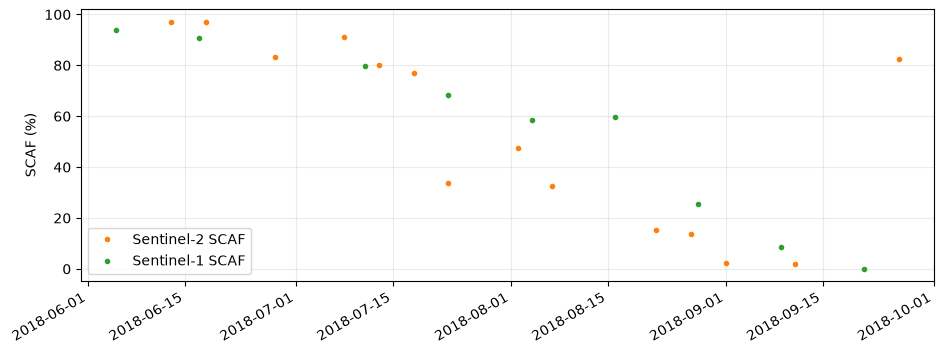

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(s2_scaf.index, s2_scaf.values, marker=".", linestyle="", label="Sentinel-2 SCAF", color='C1')
ax.plot(s1_scaf.index, s1_scaf.values, marker=".", linestyle="", label="Sentinel-1 SCAF", color='C2')
ax.set(ylabel="SCAF (%)")
ax.grid(alpha=0.25)
ax.legend()
ax.set_xlim(
    date.fromisoformat(start_date) - timedelta(days=1),
    date.fromisoformat(end_date) + timedelta(days=1),
)
fig.autofmt_xdate()
plt.show()